# 08 · Traffic-adjusted hotspots: KSI risk per vehicle-km on major roads

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/08_traffic_adjusted_hotspots.ipynb)

**Why:** notebook 05 found that 936 of the 1,002 Gi\* count hotspots are among the busiest 10% of
hexagons, and only 8 are also hot on KSI share. Counts mostly follow traffic. This notebook
divides KSI collisions by **traffic exposure** (vehicle-km from DfT traffic counts) to ask
where a journey is riskier, not just where collisions pile up.

**Data:** DfT road traffic statistics, annual average daily flow (AADF) by count point,
2015-2019 (OGL v3.0), and STATS19 collisions 2015-2019 on major roads.

**Steps**
1. Understand the traffic file; scope to major roads (where link lengths exist).
2. Match each major-road collision to the nearest count point on the same road, same year,
   within 2 km (5 km as a sensitivity check), using British National Grid metres.
3. KSI rate per 100 million vehicle-km per link with exact Poisson CIs, and empirical Bayes
   (Poisson-gamma) shrinkage within road group.
4. Gi\* (k = 6, 999 permutations, BH FDR 0.05) on EB KSI rates per H3 resolution-7 hexagon,
   compared with notebook 05's count hotspots on the same hexagons.

**Results (this run):** 
- 276,079 of 312,386 major-road collisions (88.4%) matched to a same-road count point within
  2 km (median distance 460 m; 97.6% within 5 km).
- Major roads 2015-2019: **2.76 KSI collisions per 100 million vehicle-km** (motorways 0.51,
  trunk A roads 1.42, principal A roads 4.85).
- Gi\* on the empirical Bayes KSI rate per vehicle-km: **255 hot and 0 cold** of 7,889
  hexagons. Of the 839 notebook-05 count hotspots on the same hexagons, **216 are also rate
  hotspots** (Jaccard 0.246); 623 are busy places whose risk per vehicle-km is not
  significantly high.
- London keeps 61.3% of its count hotspots as rate hotspots; the North West 8.9% and the West
  Midlands 9.1%. The South East has 26 rate hotspots that are not count hotspots.
- Sensitivity of the rate-hot set (Jaccard with the primary run): 5 km cap 0.818, exposure
  minimum halved 0.832, doubled 0.773.

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", DATA_DIR)

import time

import folium
import h3
from branca.colormap import LinearColormap
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch

from src import spatial, traffic

YEARS = (2015, 2019)
GB_RES, K = 7, 6
PER = 1e8  # rates per 100 million vehicle-km
AADF_PATH = RAW / config.AADF_RAW_FILE
if not AADF_PATH.exists():
    from src import download

    download.main(["--only", "aadf", "aadf_metadata"])

DATA_DIR = data


## 1. Traffic data: what the AADF file contains

In [3]:
header = pd.read_csv(AADF_PATH, nrows=0).columns.tolist()
print(f"{len(header)} columns in the real file:", header)
aadf_raw = traffic.load_aadf(AADF_PATH, years=YEARS)
print(f"\nRows {YEARS[0]}-{YEARS[1]}: {len(aadf_raw):,} (one row per count point per year)")
display(aadf_raw.groupby(["year", "road_type"]).size().unstack().assign(total=lambda d: d.sum(axis=1)))
cats = (aadf_raw.groupby("road_category").agg(rows=("count_point_id", "size"),
                                               count_points=("count_point_id", "nunique"),
                                               share_with_link_length=("link_length_km", lambda s: s.notna().mean()))
        .assign(description=lambda d: d.index.map(traffic.ROAD_CATEGORIES)))
display(cats.style.format({"share_with_link_length": "{:.1%}"}))
print("Share of rows with link_length_km, by road type:",
      aadf_raw.groupby("road_type")["link_length_km"].apply(lambda s: round(s.notna().mean(), 4)).to_dict())
cp_len = aadf_raw.groupby(["road_type", "count_point_id"])["link_length_km"].apply(lambda s: s.notna().any())
print("Share of count points with a link_length_km (any year), by road type:",
      cp_len.groupby(level=0).mean().round(4).to_dict(), "| count points:", cp_len.groupby(level=0).size().to_dict())
mix = pd.crosstab(aadf_raw["road_type"], aadf_raw["estimation_method"], normalize="index")
print("Estimation method by road type (share of rows):")
display(mix.style.format("{:.1%}"))
print("Detailed method, major roads:",
      aadf_raw.loc[aadf_raw["road_type"] == "Major", "estimation_method_detailed"].value_counts(normalize=True)
      .round(3).to_dict())
print("Road names that are not plain M<n> / A<n> / A<n>(M) (major roads):",
      traffic.describe_road_names(aadf_raw.loc[aadf_raw["road_type"] == "Major", "road_name"]))

34 columns in the real file: ['count_point_id', 'year', 'region_id', 'region_name', 'region_ons_code', 'local_authority_id', 'local_authority_name', 'local_authority_code', 'road_name', 'road_category', 'road_type', 'start_junction_road_name', 'end_junction_road_name', 'easting', 'northing', 'latitude', 'longitude', 'link_length_km', 'link_length_miles', 'estimation_method', 'estimation_method_detailed', 'pedal_cycles', 'two_wheeled_motor_vehicles', 'cars_and_taxis', 'buses_and_coaches', 'LGVs', 'HGVs_2_rigid_axle', 'HGVs_3_rigid_axle', 'HGVs_4_or_more_rigid_axle', 'HGVs_3_or_4_articulated_axle', 'HGVs_5_articulated_axle', 'HGVs_6_articulated_axle', 'all_HGVs', 'all_motor_vehicles']



Rows 2015-2019: 128,836 (one row per count point per year)


road_type,Major,Minor,total
year,,,
2015,18050,4704,22754
2016,18083,4703,22786
2017,18154,4696,22850
2018,18193,9350,27543
2019,18197,14706,32903


,rows,count_points,share_with_link_length,description
road_category,,,,
MB,7391,2318,0.0%,"Minor road, class B"
MCU,30768,12603,0.0%,"Minor road, class C or unclassified"
PA,73924,15496,100.0%,Principal A road
PM,188,43,100.0%,Principal motorway
TA,10715,2379,100.0%,Trunk A road
TM,5850,1253,100.0%,Trunk motorway


Share of rows with link_length_km, by road type: {'Major': 1.0, 'Minor': 0.0}


Share of count points with a link_length_km (any year), by road type: {'Major': 1.0, 'Minor': 0.0} | count points: {'Major': 19158, 'Minor': 14904}
Estimation method by road type (share of rows):


estimation_method,Counted,Estimated
road_type,,
Major,22.3%,77.7%
Minor,82.0%,18.0%


Detailed method, major roads: {'Estimated using AADF from previous year on this link': 0.715, 'Manual count': 0.168, 'Estimated from nearby links': 0.062, 'Automatic counter': 0.035, 'Dependent on a neighbouring counted link': 0.017, 'Dependent on an automatic counter on a neighbouring link': 0.003}
Road names that are not plain M<n> / A<n> / A<n>(M) (major roads): {'M6(T)': 156, 'A57M': 30, 'A167M': 30, 'A38M': 20, 'A329M': 17, 'A74M': 17, 'A64M': 15, 'A58M': 15, 'A601M': 10, 'A194M': 6}


**Scope: major roads only.** Link lengths, and therefore vehicle-km, exist only for major roads
(motorways and A roads): every major-road row has a `link_length_km` and no minor-road row
does (shares printed above). Minor-road count points are a sample used by DfT for regional
estimates and do not describe a road link. So everything below is about **major roads**.
Most major-road AADFs are *estimated* from earlier counts on the same link rather than counted
in that year (mix above), so a link's flow is an estimate, not a measurement. DfT's metadata
also warns that AADFs at different count points should not be added together; vehicle-km
(AADF x link length x 365) is the quantity that can be summed.

In [4]:
aadf = traffic.clean_aadf(aadf_raw)
major = aadf[aadf["is_major"]]
print(f"Major-road rows: {len(major):,}; usable for exposure (coordinates, link length > 0, AADF >= 0): "
      f"{int(major['usable'].sum()):,}")
points = major[major["usable"]].assign(road_name=lambda d: d["road_name_norm"])
years_per_point = points.groupby("count_point_id")["year"].nunique()
print(f"Major-road count points: {len(years_per_point):,}; with AADF in all 5 years: "
      f"{int((years_per_point == 5).sum()):,}")
moved = points.groupby("count_point_id")[["easting", "northing"]].nunique().max(axis=1) > 1
relength = points.groupby("count_point_id")["link_length_km"].nunique() > 1
print(f"Count points whose location changes between years: {int(moved.sum()):,}; whose link length changes: "
      f"{int(relength.sum()):,}. So collisions are matched per year (step 2).")
vkm_year = points.pivot_table(index="year", columns="road_group", values="vehicle_km", aggfunc="sum") / 1e9
vkm_year["all major roads"] = vkm_year.sum(axis=1)
print("Vehicle-km per year (billions) = AADF all_motor_vehicles x link_length_km x 365:")
display(vkm_year.style.format("{:,.1f}"))

Major-road rows: 90,677; usable for exposure (coordinates, link length > 0, AADF >= 0): 90,677
Major-road count points: 19,158; with AADF in all 5 years: 17,139
Count points whose location changes between years: 2,339; whose link length changes: 3,851. So collisions are matched per year (step 2).
Vehicle-km per year (billions) = AADF all_motor_vehicles x link_length_km x 365:


road_group,Motorway,Principal A road,Trunk A road,all major roads
year,,,,
2015,107.0,160.6,66.3,333.9
2016,108.6,163.3,69.1,341.1
2017,110.4,164.1,71.6,346.1
2018,111.1,166.2,72.8,350.2
2019,113.5,167.4,74.3,355.2


## 2. Matching collisions to traffic links

Major-road collisions 2015-2019 are those whose `first_road_class` is Motorway, A(M) or A and
whose coordinates are valid. Their road name is built from class and `first_road_number`
(`M25`, `A1`, `A1(M)`), the same format as the cleaned AADF names. Each collision is assigned to
the nearest count point **on the same road, with an AADF in the same year**, using British
National Grid easting/northing (metres). The primary distance cap is 2 km; 5 km is a
sensitivity check.

In [5]:
CC = ["collision_index", "collision_year", "first_road_class", "first_road_class_label", "first_road_number",
      "location_easting_osgr", "location_northing_osgr", "coord_valid", "ksi", "latitude", "longitude",
      "junction_detail_historic_label"]
coll = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=CC)
coll = coll[coll["collision_year"].between(*YEARS)]
is_major = coll["first_road_class"].isin(list(traffic.STATS19_MAJOR_CLASSES))
print(f"Collisions {YEARS[0]}-{YEARS[1]}: {len(coll):,}; on major roads: {int(is_major.sum()):,}")
mc = coll[is_major & coll["coord_valid"]].copy()
no_grid = mc["location_easting_osgr"].isna() | mc["location_northing_osgr"].isna()
print(f"With valid coordinates: {len(mc):,}; of which without a grid reference (excluded): {int(no_grid.sum()):,}")
mc = mc[~no_grid]
mc["road_name"] = traffic.collision_road_name(mc["first_road_class"], mc["first_road_number"])
mc["ksi"] = mc["ksi"].astype(int)
print("By road class:", mc["first_road_class_label"].value_counts().loc[lambda v: v > 0].to_dict())
print("Most common road names:", mc["road_name"].value_counts().head(8).to_dict())
print(f"Road name also present among usable AADF count points: {mc['road_name'].isin(set(points['road_name'])).mean():.2%}")

Collisions 2015-2019: 646,830; on major roads: 312,466
With valid coordinates: 312,386; of which without a grid reference (excluded): 0


By road class: {'A': 287961, 'Motorway': 22616, 'A(M)': 1809}
Most common road names: {'A38': 3419, 'A4': 3392, 'A23': 3294, 'M25': 3267, 'A1': 3258, 'A5': 2922, 'A3': 2922, 'A40': 2894}
Road name also present among usable AADF count points: 99.88%


Matching at two caps took 32 s


,2 km cap,5 km cap
reason,,
matched,"276,079","304,857"
missing road number,0,0
no same-road count point,521,521
beyond distance cap,"35,786","7,008"
total,"312,386","312,386"


Share of major-road collisions matched: {'2 km cap': '88.4%', '5 km cap': '97.6%'}
Distance to the nearest same-road count point (all collisions with one): median 460 m, p90 2,206 m, p99 7,055 m
Share matched at 2 km by road class: {'A': 0.893, 'A(M)': 0.753, 'Motorway': 0.773}
KSI share: matched 0.1727, unmatched 0.2437


19:28:15 INFO src.evaluate: Saved figure reports/figures/08_match_distance.png


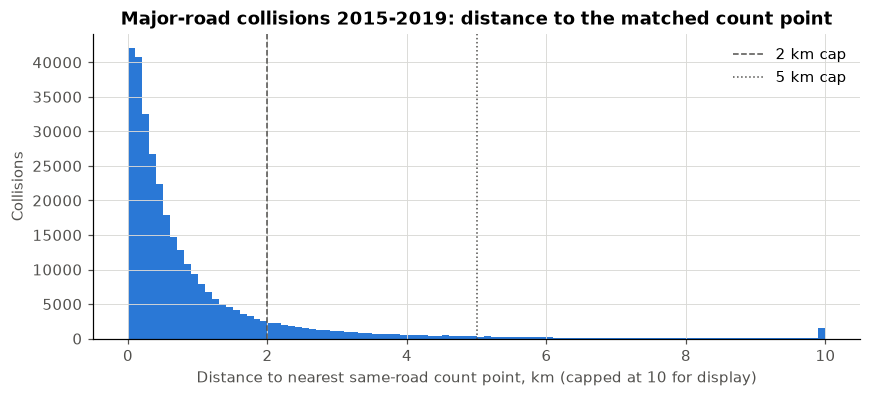

In [6]:
def match(cap_m):
    query = pd.DataFrame({"road_name": mc["road_name"], "easting": mc["location_easting_osgr"].astype(float),
                          "northing": mc["location_northing_osgr"].astype(float),
                          "year": mc["collision_year"].astype(int)}, index=mc.index)
    return traffic.match_to_count_points(query, points, cap_m=cap_m)


t0 = time.time()
m2, m5 = match(2_000), match(5_000)
print(f"Matching at two caps took {time.time() - t0:.0f} s")
summary = pd.DataFrame({"2 km cap": m2["reason"].value_counts(), "5 km cap": m5["reason"].value_counts()}).fillna(0)
summary = summary.reindex(["matched", *traffic.UNMATCHED_REASONS], fill_value=0).astype(int)
summary.loc["total"] = summary.sum()
share = (summary.loc["matched"] / len(mc)).rename("share matched")
display(summary.style.format("{:,}"))
print("Share of major-road collisions matched:", {k: f"{v:.1%}" for k, v in share.items()})
d = m2["distance_m"].dropna()
print(f"Distance to the nearest same-road count point (all collisions with one): median {d.median():,.0f} m, "
      f"p90 {d.quantile(0.9):,.0f} m, p99 {d.quantile(0.99):,.0f} m")
mc["count_point_id"], mc["distance_m"], mc["reason"] = m2["count_point_id"], m2["distance_m"], m2["reason"]
mc["count_point_id_5km"] = m5["count_point_id"]
by_class = mc.groupby("first_road_class_label", observed=True)["reason"].apply(lambda s: (s == "matched").mean())
print("Share matched at 2 km by road class:", by_class.round(3).to_dict())
print(f"KSI share: matched {mc.loc[mc['reason'] == 'matched', 'ksi'].mean():.4f}, "
      f"unmatched {mc.loc[mc['reason'] != 'matched', 'ksi'].mean():.4f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.minimum(d, 10_000) / 1000, bins=100, color=evaluate.PALETTE[0])
for cap, ls in [(2, "--"), (5, ":")]:
    ax.axvline(cap, color="#52514e", linestyle=ls, linewidth=1, label=f"{cap} km cap")
ax.set_xlabel("Distance to nearest same-road count point, km (capped at 10 for display)")
ax.set_ylabel("Collisions")
ax.set_title("Major-road collisions 2015-2019: distance to the matched count point")
ax.legend()
evaluate.save_fig(fig, "08_match_distance")
plt.show()

## 3. KSI risk per vehicle-km on each link

Per count point (link): matched collisions and KSI collisions, and vehicle-km summed over the
years with an AADF, 2015-2019 (collisions are only matched to a link in years it has an AADF,
so numerator and exposure cover the same years). Rates are per 100 million vehicle-km with
exact (Garwood) Poisson 95% intervals.

**Empirical Bayes.** A link with little traffic and one KSI collision gets a huge raw rate by
chance; next period it would most likely be lower (regression to the mean). The Poisson-gamma
EB estimate is a weighted average of the link's raw rate and its road group's mean rate
(motorway, trunk A road, principal A road), with weight `A / (A + m / E)`: the more exposure
E a link has, the more its own data count. The prior is fitted by the method of moments within
each road group (`evaluate.empirical_bayes_rates`).

**Exposure minimum for ranking: 20 million vehicle-km over 2015-2019.** Below it a link's own
data are too thin to rank on even after shrinkage. The cell prints how many KSI collisions a
link at the threshold would be expected to have at its group's mean rate; the threshold keeps
about one expected KSI collision for principal A roads, the group with the highest rate.
Every link stays in the hexagon totals in step 4; the minimum only applies to ranking.

In [7]:
EXPOSURE_MIN = 2e7

link = points.groupby("count_point_id").agg(
    road_name=("road_name", "last"), road_group=("road_group", "last"), road_category=("road_category", "last"),
    vehicle_km=("vehicle_km", "sum"), years=("year", "nunique"), lat=("latitude", "last"), lon=("longitude", "last"),
    start=("start_junction_road_name", "last"), end=("end_junction_road_name", "last"),
    local_authority=("local_authority_name", "last"), region=("region_name", "last"))
matched = mc[mc["reason"] == "matched"]
link = link.join(matched.groupby("count_point_id").agg(collisions=("ksi", "size"), ksi=("ksi", "sum")))
link[["collisions", "ksi"]] = link[["collisions", "ksi"]].fillna(0).astype(int)
link["ksi_rate"], link["ksi_rate_low"], link["ksi_rate_high"] = evaluate.poisson_rate_ci(
    link["ksi"], link["vehicle_km"], per=PER)
eb = evaluate.empirical_bayes_rates(link["ksi"], link["vehicle_km"], groups=link["road_group"])
link["eb_ksi_rate"], link["eb_weight"] = eb["eb_rate"] * PER, eb["weight"]
group_prior = eb.groupby(link["road_group"])[["prior_mean", "prior_var"]].first()
group = link.groupby("road_group").agg(links=("ksi", "size"), vehicle_km_bn=("vehicle_km", lambda s: s.sum() / 1e9),
                                        collisions=("collisions", "sum"), ksi=("ksi", "sum"))
group["ksi_per_100m_vkm"] = group["ksi"] / (group["vehicle_km_bn"] * 1e9) * PER
group["prior_sd_per_100m_vkm"] = np.sqrt(group_prior["prior_var"]) * PER
group["expected_ksi_at_minimum"] = group["ksi_per_100m_vkm"] * EXPOSURE_MIN / PER
group["links_above_minimum"] = link.groupby("road_group")["vehicle_km"].apply(lambda s: int((s >= EXPOSURE_MIN).sum()))
total_rate = link["ksi"].sum() / link["vehicle_km"].sum() * PER
print(f"{len(link):,} links; {link['ksi'].sum():,} matched KSI collisions on {link['vehicle_km'].sum() / 1e9:,.1f} "
      f"billion vehicle-km: {total_rate:.2f} KSI per 100M vehicle-km overall")
display(group.style.format({"vehicle_km_bn": "{:,.1f}", "ksi_per_100m_vkm": "{:.2f}", "prior_sd_per_100m_vkm": "{:.2f}",
                            "expected_ksi_at_minimum": "{:.2f}", "collisions": "{:,}", "ksi": "{:,}", "links": "{:,}"}))
ranked = link[link["vehicle_km"] >= EXPOSURE_MIN]
print(f"Links at or above {EXPOSURE_MIN / 1e6:.0f} million vehicle-km: {len(ranked):,} of {len(link):,}, holding "
      f"{ranked['vehicle_km'].sum() / link['vehicle_km'].sum():.1%} of vehicle-km and "
      f"{ranked['ksi'].sum() / link['ksi'].sum():.1%} of matched KSI collisions")

19,158 links; 47,668 matched KSI collisions on 1,726.5 billion vehicle-km: 2.76 KSI per 100M vehicle-km overall


,links,vehicle_km_bn,collisions,ksi,ksi_per_100m_vkm,prior_sd_per_100m_vkm,expected_ksi_at_minimum,links_above_minimum
road_group,,,,,,,,
Motorway,"1,294",550.7,"18,862","2,793",0.51,1.34,0.10,1121
Principal A road,"15,496",821.7,"232,853","39,861",4.85,8.89,0.97,10081
Trunk A road,"2,368",354.1,"24,364","5,014",1.42,3.84,0.28,1863


Links at or above 20 million vehicle-km: 13,065 of 19,158, holding 96.6% of vehicle-km and 80.5% of matched KSI collisions


In [8]:
SHOW = ["road_name", "road_group", "local_authority", "start", "end", "vehicle_km", "collisions", "ksi",
        "ksi_rate", "ksi_rate_low", "ksi_rate_high", "eb_ksi_rate", "eb_weight"]
FMT = {"vehicle_km": lambda v: f"{v / 1e6:,.1f}M", "ksi_rate": "{:.2f}", "ksi_rate_low": "{:.2f}",
       "ksi_rate_high": "{:.2f}", "eb_ksi_rate": "{:.2f}", "eb_weight": "{:.2f}"}
top_raw = ranked.nlargest(20, "ksi_rate")
top_eb = ranked.nlargest(20, "eb_ksi_rate")
top_count = ranked.nlargest(20, "ksi")
print("Top 20 links by RAW KSI rate (>= minimum exposure), with their EB rate:")
display(top_raw[SHOW].style.format(FMT))
print(f"Of the top 20 by raw rate, {len(set(top_raw.index) & set(top_eb.index))} are also in the top 20 by EB rate; "
      f"median EB weight {top_raw['eb_weight'].median():.2f}; median vehicle-km {top_raw['vehicle_km'].median() / 1e6:.1f}M")
wild = link.nlargest(20, "ksi_rate")
print(f"Without the exposure minimum, the top 20 raw rates come from links with median "
      f"{wild['vehicle_km'].median() / 1e6:.2f}M vehicle-km and median {wild['ksi'].median():.0f} KSI collision(s): "
      f"raw rates {wild['ksi_rate'].min():,.0f}-{wild['ksi_rate'].max():,.0f} per 100M vehicle-km, EB rates "
      f"{wild['eb_ksi_rate'].min():.2f}-{wild['eb_ksi_rate'].max():.2f} (median EB weight {wild['eb_weight'].median():.3f}); "
      f"{len(set(wild.index) & set(link.nlargest(20, 'eb_ksi_rate').index))} of them stay in the all-links EB top 20")
print("Top 20 links by EB KSI rate:")
display(top_eb[SHOW].style.format(FMT))
print("Top 20 links by KSI count:")
display(top_count[SHOW].style.format(FMT))
both = set(top_count.index) & set(top_eb.index)
print(f"Overlap between top 20 by KSI count and top 20 by EB KSI rate: {len(both)} links "
      f"(Jaccard {evaluate.jaccard(set(top_count.index), set(top_eb.index)):.3f})")
print("Road groups: top 20 by count", top_count["road_group"].value_counts().to_dict(), "| top 20 by EB rate",
      top_eb["road_group"].value_counts().to_dict())
print(f"Median vehicle-km: top 20 by count {top_count['vehicle_km'].median() / 1e6:,.1f}M, "
      f"top 20 by EB rate {top_eb['vehicle_km'].median() / 1e6:,.1f}M")

Top 20 links by RAW KSI rate (>= minimum exposure), with their EB rate:


,road_name,road_group,local_authority,start,end,vehicle_km,collisions,ksi,ksi_rate,ksi_rate_low,ksi_rate_high,eb_ksi_rate,eb_weight
count_point_id,,,,,,,,,,,,,
47895,A259,Principal A road,Brighton and Hove,A2010,A23,33.8M,134,37,109.36,77.00,150.74,93.33,0.85
47661,A3211,Principal A road,Westminster,A302,A400,20.4M,105,21,102.86,63.67,157.24,80.22,0.77
7571,A3036,Principal A road,Wandsworth,A3220,LA Boundary,25.0M,135,23,92.14,58.41,138.26,74.93,0.80
46277,A24,Principal A road,Wandsworth,A217,A214,41.4M,244,38,91.83,64.98,126.04,80.60,0.87
6632,A105,Principal A road,Hackney,A503,LA Boundary,21.2M,162,19,89.67,53.99,140.03,70.63,0.78
6299,A2010,Principal A road,Brighton and Hove,A259,A270,21.9M,92,18,82.32,48.79,130.09,65.35,0.78
6094,A2,Principal A road,Southwark,A3/A2198,A201/A100,21.9M,128,18,82.30,48.78,130.07,65.34,0.78
17585,A4020,Principal A road,Ealing,A406(T),A4000 Gunnersbury Lane,31.3M,163,25,79.75,51.61,117.72,67.49,0.84
37101,A400,Principal A road,Camden,A5204,A501,20.5M,99,16,78.17,44.68,126.95,61.27,0.77


Of the top 20 by raw rate, 17 are also in the top 20 by EB rate; median EB weight 0.81; median vehicle-km 25.9M
Without the exposure minimum, the top 20 raw rates come from links with median 0.50M vehicle-km and median 2 KSI collision(s): raw rates 373-5,228 per 100M vehicle-km, EB rates 11.62-213.21 (median EB weight 0.071); 5 of them stay in the all-links EB top 20
Top 20 links by EB KSI rate:


,road_name,road_group,local_authority,start,end,vehicle_km,collisions,ksi,ksi_rate,ksi_rate_low,ksi_rate_high,eb_ksi_rate,eb_weight
count_point_id,,,,,,,,,,,,,
47895,A259,Principal A road,Brighton and Hove,A2010,A23,33.8M,134,37,109.36,77.00,150.74,93.33,0.85
46277,A24,Principal A road,Wandsworth,A217,A214,41.4M,244,38,91.83,64.98,126.04,80.60,0.87
47661,A3211,Principal A road,Westminster,A302,A400,20.4M,105,21,102.86,63.67,157.24,80.22,0.77
7571,A3036,Principal A road,Wandsworth,A3220,LA Boundary,25.0M,135,23,92.14,58.41,138.26,74.93,0.80
6632,A105,Principal A road,Hackney,A503,LA Boundary,21.2M,162,19,89.67,53.99,140.03,70.63,0.78
17585,A4020,Principal A road,Ealing,A406(T),A4000 Gunnersbury Lane,31.3M,163,25,79.75,51.61,117.72,67.49,0.84
6299,A2010,Principal A road,Brighton and Hove,A259,A270,21.9M,92,18,82.32,48.79,130.09,65.35,0.78
6094,A2,Principal A road,Southwark,A3/A2198,A201/A100,21.9M,128,18,82.30,48.78,130.07,65.34,0.78
56175,A11,Principal A road,Tower Hamlets,A107,A1205,65.4M,291,46,70.39,51.53,93.89,64.76,0.91


Top 20 links by KSI count:


,road_name,road_group,local_authority,start,end,vehicle_km,collisions,ksi,ksi_rate,ksi_rate_low,ksi_rate_high,eb_ksi_rate,eb_weight
count_point_id,,,,,,,,,,,,,
6201,A11,Principal A road,Tower Hamlets,A1205,A12,91.8M,468,61,66.47,50.84,85.38,62.61,0.94
56175,A11,Principal A road,Tower Hamlets,A107,A1205,65.4M,291,46,70.39,51.53,93.89,64.76,0.91
29030,A21,Principal A road,Lewisham,A205,A20,130.0M,362,39,29.99,21.33,41.00,28.86,0.95
46218,A13,Principal A road,Tower Hamlets,A11/A1202 mid-junction,A126,100.5M,311,38,37.83,26.77,51.92,35.93,0.94
46269,A23,Principal A road,Lambeth,A205,A204,62.4M,265,38,60.89,43.09,83.58,55.88,0.91
46277,A24,Principal A road,Wandsworth,A217,A214,41.4M,244,38,91.83,64.98,126.04,80.60,0.87
47895,A259,Principal A road,Brighton and Hove,A2010,A23,33.8M,134,37,109.36,77.00,150.74,93.33,0.85
56771,A215,Principal A road,Southwark,A202,A3,56.6M,259,37,65.40,46.04,90.14,59.47,0.90
26270,A23,Principal A road,Lambeth,A214/A216,A205,107.9M,270,32,29.65,20.28,41.85,28.31,0.95


Overlap between top 20 by KSI count and top 20 by EB KSI rate: 8 links (Jaccard 0.250)
Road groups: top 20 by count {'Principal A road': 20} | top 20 by EB rate {'Principal A road': 20}
Median vehicle-km: top 20 by count 67.2M, top 20 by EB rate 28.5M


19:28:16 INFO src.evaluate: Saved figure reports/figures/08_raw_vs_eb_rates.png


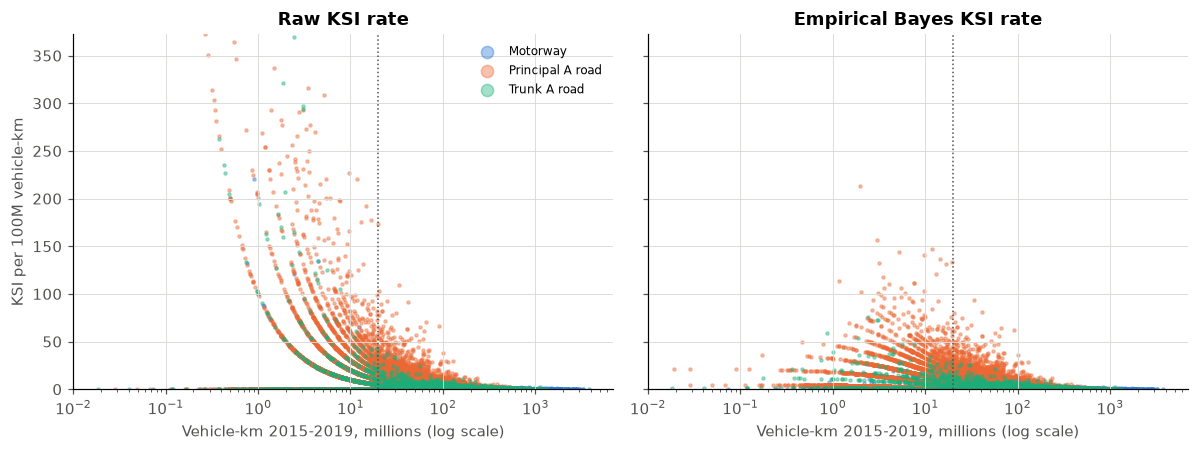

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, title in [(axes[0], "ksi_rate", "Raw KSI rate"), (axes[1], "eb_ksi_rate", "Empirical Bayes KSI rate")]:
    for i, (g, part) in enumerate(link.groupby("road_group")):
        ax.scatter(part["vehicle_km"] / 1e6, part[col], s=4, alpha=0.4, color=evaluate.PALETTE[i], label=g)
    ax.set_xscale("log")
    ax.axvline(EXPOSURE_MIN / 1e6, color="#52514e", linestyle=":", linewidth=1)
    ax.set_xlabel("Vehicle-km 2015-2019, millions (log scale)")
    ax.set_title(title)
axes[0].set_ylabel("KSI per 100M vehicle-km")
axes[0].set_ylim(0, link["ksi_rate"].quantile(0.999))
axes[0].legend(markerscale=4, fontsize=8)
fig.tight_layout()
evaluate.save_fig(fig, "08_raw_vs_eb_rates")
plt.show()

## 4. Traffic-adjusted hotspots on H3 hexagons

Each link's vehicle-km, collisions and KSI collisions are assigned to the resolution-7 hexagon
of its **count point**. This is an approximation: a long link crosses several hexagons, but
all of its traffic and its matched collisions are put in one, so numerator and exposure stay
together. Hexagon rates are then shrunk by empirical Bayes (one prior across hexagons), and
Gi\* (k = 6 nearest hexagons, 999 permutations, p from the permutation z, BH FDR 0.05) is run
on the EB KSI rate of hexagons with at least the exposure minimum.

Notebook 05's count hotspots are recomputed with exactly the same code (KSI counts per
hexagon, all 2015-2019 collisions) and then restricted to the hexagons analysed here.

In [10]:
def hex_rates(link_frame, exposure_min, seed=config.RANDOM_STATE):
    """Hexagon totals, EB KSI rate, and Gi* on the EB rate of hexagons above the exposure minimum."""
    lf = link_frame.assign(cell=spatial.to_cells(link_frame["lat"], link_frame["lon"], GB_RES))
    hx = lf.groupby("cell").agg(links=("ksi", "size"), vehicle_km=("vehicle_km", "sum"),
                                collisions=("collisions", "sum"), ksi=("ksi", "sum"))
    hx["eb_ksi_rate"] = evaluate.empirical_bayes_rates(hx["ksi"], hx["vehicle_km"])["eb_rate"] * PER
    hx = hx.join(spatial.cell_centroids(hx.index))
    sel = hx[hx["vehicle_km"] >= exposure_min].copy()
    gi = spatial.gi_star(sel["eb_ksi_rate"], spatial.knn_weights(spatial.local_xy_km(sel["lat"], sel["lon"]), K),
                         seed=seed, index=sel.index)
    sel["gi_z"], sel["gi_q"], sel["cluster"] = gi["z_sim"], gi["q_bh"], gi["cluster"]
    return hx, sel


hex_all, hexr = hex_rates(link, EXPOSURE_MIN)
rc = hexr["cluster"].value_counts()
print(f"{len(hex_all):,} hexagons contain a major-road count point; {len(hexr):,} have >= "
      f"{EXPOSURE_MIN / 1e6:.0f}M vehicle-km and enter Gi*")
print(f"Gi* on EB KSI rate (FDR 0.05): {rc.get('hot', 0):,} hot and {rc.get('cold', 0):,} cold hexagons")
rate_hot = set(hexr.index[hexr["cluster"] == "hot"])
rate_cold = set(hexr.index[hexr["cluster"] == "cold"])
print("Rate-hot hexagons by road group of their busiest link:",
      link.assign(cell=spatial.to_cells(link["lat"], link["lon"], GB_RES)).sort_values("vehicle_km")
      .drop_duplicates("cell", keep="last").set_index("cell").loc[list(rate_hot), "road_group"].value_counts().to_dict())

8,644 hexagons contain a major-road count point; 7,889 have >= 20M vehicle-km and enter Gi*
Gi* on EB KSI rate (FDR 0.05): 255 hot and 0 cold hexagons
Rate-hot hexagons by road group of their busiest link: {'Principal A road': 234, 'Trunk A road': 13, 'Motorway': 8}


In [11]:
# Notebook 05's count hotspots, recomputed with the same code and inputs.
c05 = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=["collision_year", "latitude", "longitude",
                                                                      "coord_valid", "ksi"])
c05 = c05[c05["collision_year"].between(*YEARS) & c05["coord_valid"]]
c05 = c05.assign(cell=spatial.to_cells(c05["latitude"], c05["longitude"], GB_RES), ksi=c05["ksi"].astype(int))
hex05 = c05.groupby("cell").agg(collisions=("ksi", "size"), ksi=("ksi", "sum")).join(
    spatial.cell_centroids(c05["cell"].unique()))
gi05 = spatial.gi_star(hex05["ksi"], spatial.knn_weights(spatial.local_xy_km(hex05["lat"], hex05["lon"]), K),
                       index=hex05.index)
count_hot_all = set(hex05.index[gi05["cluster"] == "hot"])
print(f"Notebook 05 count hotspots recomputed: {len(count_hot_all):,} hot hexagons (notebook 05 printed 1,002)")
same = set(hexr.index)
count_hot = count_hot_all & same
print(f"Restricted to the {len(same):,} hexagons analysed here: {len(count_hot):,} count hotspots")
print(f"Count-hot AND rate-hot: {len(count_hot & rate_hot):,}; count-hot only: {len(count_hot - rate_hot):,}; "
      f"rate-hot only: {len(rate_hot - count_hot):,}; Jaccard {evaluate.jaccard(count_hot, rate_hot):.3f}")
print(f"Count hotspots that are rate-COLD: {len(count_hot & rate_cold):,}")
cmp = hexr.assign(count_hot=hexr.index.isin(count_hot), rate_hot=hexr.index.isin(rate_hot))
prof = cmp.groupby(["count_hot", "rate_hot"]).agg(hexagons=("ksi", "size"),
                                                  median_vehicle_km_m=("vehicle_km", lambda s: s.median() / 1e6),
                                                  ksi=("ksi", "sum"), vehicle_km=("vehicle_km", "sum"))
prof["ksi_per_100m_vkm"] = prof["ksi"] / prof["vehicle_km"] * PER
display(prof.drop(columns="vehicle_km").style.format({"median_vehicle_km_m": "{:,.1f}", "ksi_per_100m_vkm": "{:.2f}"}))
hex_region = (link.assign(cell=spatial.to_cells(link["lat"], link["lon"], GB_RES)).sort_values("vehicle_km")
              .drop_duplicates("cell", keep="last").set_index("cell")["region"])
kind = pd.Series(np.select([cmp["count_hot"] & cmp["rate_hot"], cmp["count_hot"], cmp["rate_hot"]],
                           ["count-hot and rate-hot", "count-hot only", "rate-hot only"], "neither"), index=cmp.index)
by_region = pd.crosstab(hex_region.reindex(cmp.index), kind).drop(columns="neither")
by_region["share_of_count_hot_also_rate_hot"] = by_region["count-hot and rate-hot"] / (
    by_region["count-hot and rate-hot"] + by_region["count-hot only"])
print("Hexagons by region (region of the hexagon's busiest link):")
display(by_region.sort_values("count-hot only", ascending=False).style.format(
    {"share_of_count_hot_also_rate_hot": "{:.1%}"}, na_rep="-"))

Notebook 05 count hotspots recomputed: 1,002 hot hexagons (notebook 05 printed 1,002)
Restricted to the 7,889 hexagons analysed here: 839 count hotspots
Count-hot AND rate-hot: 216; count-hot only: 623; rate-hot only: 39; Jaccard 0.246
Count hotspots that are rate-COLD: 0


Hexagons by region (region of the hexagon's busiest link):


col_0,count-hot and rate-hot,count-hot only,rate-hot only,share_of_count_hot_also_rate_hot
region,,,,
North West,10,102,2,8.9%
London,141,89,4,61.3%
Yorkshire and The Humber,16,86,5,15.7%
South East,30,85,26,26.1%
West Midlands,8,80,0,9.1%
East of England,1,56,0,1.8%
East Midlands,0,40,1,0.0%
South West,0,39,1,0.0%
Scotland,9,24,0,27.3%


In [12]:
sens = {}
_, h5 = hex_rates(link.drop(columns=["collisions", "ksi"]).join(
    mc[mc["count_point_id_5km"].notna()].groupby("count_point_id_5km").agg(collisions=("ksi", "size"),
                                                                           ksi=("ksi", "sum"))).fillna(
    {"collisions": 0, "ksi": 0}), EXPOSURE_MIN)
sens["5 km cap"] = set(h5.index[h5["cluster"] == "hot"])
for label, factor in [("exposure minimum halved", 0.5), ("exposure minimum doubled", 2.0)]:
    _, hs = hex_rates(link, EXPOSURE_MIN * factor)
    sens[label] = set(hs.index[hs["cluster"] == "hot"])
rows = [{"variant": "primary (2 km, 20M vehicle-km)", "hot_hexagons": len(rate_hot), "hot_in_both": len(rate_hot),
         "jaccard_vs_primary": 1.0}]
rows += [{"variant": k, "hot_hexagons": len(v), "hot_in_both": len(v & rate_hot),
          "jaccard_vs_primary": evaluate.jaccard(v, rate_hot)} for k, v in sens.items()]
display(pd.DataFrame(rows).set_index("variant").style.format({"jaccard_vs_primary": "{:.3f}"}))

,hot_hexagons,hot_in_both,jaccard_vs_primary
variant,,,
"primary (2 km, 20M vehicle-km)",255,255,1.000
5 km cap,234,220,0.818
exposure minimum halved,256,232,0.832
exposure minimum doubled,261,225,0.773


19:28:50 INFO src.evaluate: Saved figure reports/figures/08_count_vs_rate_hotspots.png


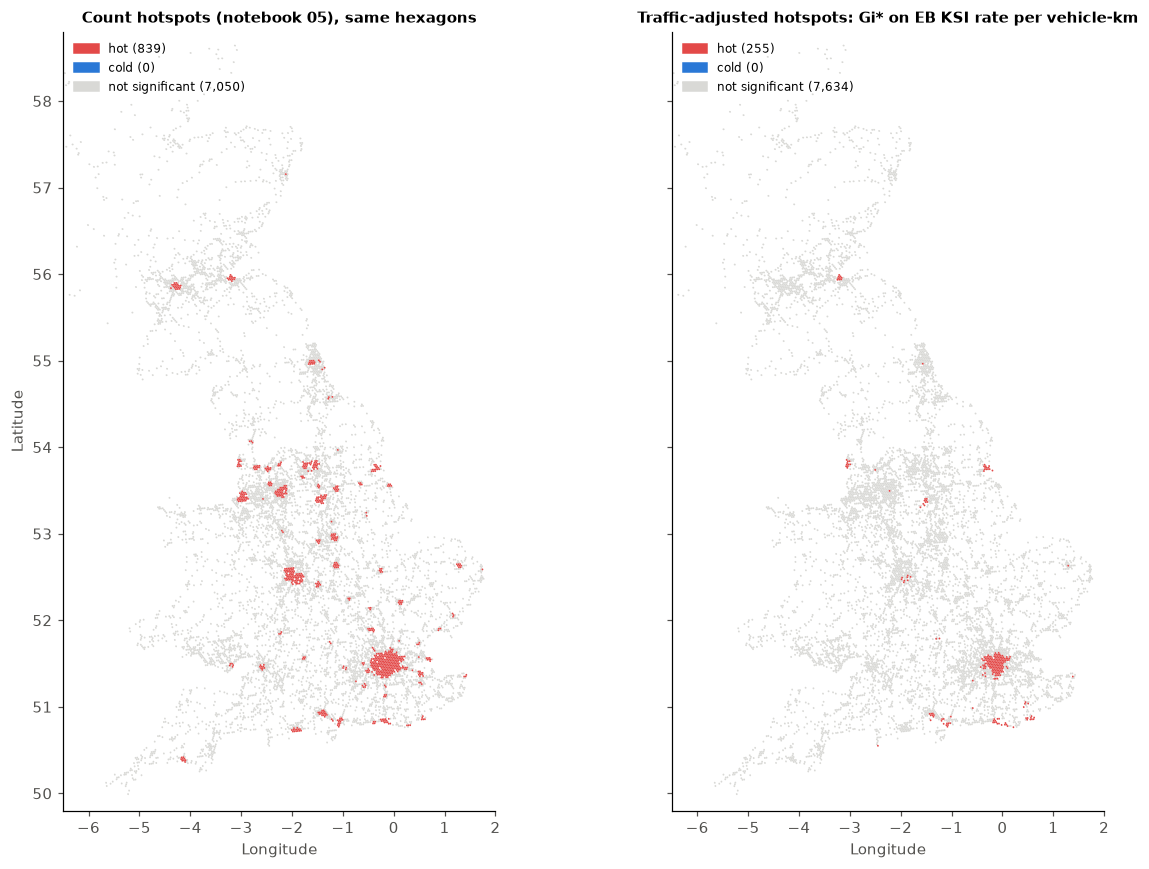

In [13]:
CLUSTER_COLOURS = {"hot": evaluate.PALETTE[7], "cold": evaluate.PALETTE[0], "not significant": "#d9d9d6"}


def hex_map(frame, ax, title):
    order = frame.sort_values("cluster", key=lambda s: s.map({"not significant": 0, "cold": 1, "hot": 2}))
    polys = [[(lon, lat) for lat, lon in h3.cell_to_boundary(c)] for c in order.index]
    ax.add_collection(PolyCollection(polys, facecolors=order["cluster"].map(CLUSTER_COLOURS), edgecolors="none"))
    ax.set_xlim(-6.5, 2.0)
    ax.set_ylim(49.8, 58.8)
    ax.set_aspect(1 / np.cos(np.deg2rad(54)))
    ax.set_xlabel("Longitude")
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    n = frame["cluster"].value_counts()
    ax.legend(handles=[Patch(color=CLUSTER_COLOURS[c], label=f"{c} ({n.get(c, 0):,})")
                       for c in ["hot", "cold", "not significant"]], loc="upper left", fontsize=8)


count_frame = hexr.assign(cluster=np.where(hexr.index.isin(count_hot), "hot", "not significant"))
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
hex_map(count_frame, axes[0], "Count hotspots (notebook 05), same hexagons")
hex_map(hexr, axes[1], "Traffic-adjusted hotspots: Gi* on EB KSI rate per vehicle-km")
axes[0].set_ylabel("Latitude")
fig.tight_layout()
evaluate.save_fig(fig, "08_count_vs_rate_hotspots")
plt.show()

In [14]:
MAP_PATH = config.REPO_ROOT / "reports" / "traffic_adjusted_map.html"


def layer(frame, cells, name, colour_col, colours, caption, show):
    part = frame.loc[sorted(cells)]
    cmap = LinearColormap(colours, vmin=float(part[colour_col].min()), vmax=float(part[colour_col].max()),
                          caption=caption)
    feats = [{"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [spatial.cell_boundary_lonlat(c)]},
              "properties": {"ksi": int(r.ksi), "vkm_m": round(float(r.vehicle_km) / 1e6, 1),
                             "eb_rate": round(float(r.eb_ksi_rate), 2), "value": round(float(r[colour_col]), 2)}}
             for c, r in part.iterrows()]
    gj = folium.GeoJson({"type": "FeatureCollection", "features": feats}, name=name, show=show,
                        style_function=lambda f: {"fillColor": cmap(f["properties"]["value"]), "color": "#52514e",
                                                  "weight": 0.3, "fillOpacity": 0.75},
                        tooltip=folium.GeoJsonTooltip(["ksi", "vkm_m", "eb_rate"],
                                                      aliases=["KSI (matched, major roads)", "Vehicle-km (millions)",
                                                               "EB KSI per 100M vehicle-km"]))
    return gj, cmap


m = folium.Map(location=[54.0, -2.5], zoom_start=6, tiles="OpenStreetMap")
count_layer, _ = layer(hexr.assign(count_ksi=hex05["ksi"].reindex(hexr.index)), count_hot,
                       f"Count hotspots ({len(count_hot):,})", "count_ksi", ["#c6dbef", "#2171b5", "#08306b"],
                       "KSI collisions per hexagon, all roads (count hotspots)", True)
rate_layer, rate_cmap = layer(hexr, rate_hot, f"Rate hotspots per vehicle-km ({len(rate_hot):,})", "eb_ksi_rate",
                              ["#fdd49e", "#fc8d59", "#d7301f", "#7f0000"], "EB KSI per 100M vehicle-km (rate hotspots)",
                              True)
count_layer.add_to(m)
rate_layer.add_to(m)
rate_cmap.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(MAP_PATH)
size = MAP_PATH.stat().st_size
assert size < 10 * 1024 * 1024
print(f"Saved {MAP_PATH.relative_to(config.REPO_ROOT)}: {size / 1e6:.2f} MB")

Saved reports/traffic_adjusted_map.html: 0.42 MB


## Conclusion


**Most count hotspots are traffic.** Of the 839 count hotspots on major-road hexagons, 623 have
no significant cluster of high KSI risk per vehicle-km. Their pooled rate (4.92 KSI per 100M
vehicle-km) is close to that of principal A roads in general (4.85). The 216 hexagons that are
hot on both measures stand out at 13.94, against 1.92 for hexagons hot on neither.

**Where busy and high-risk-per-journey differ.** In London, 141 hexagons are hot on both
measures (61.3% of its count hotspots). In the North West, West Midlands and East of England
most count hotspots disappear once traffic is accounted for (8.9%, 9.1% and 1.8% stay hot).
The South East has 26 rate-only hotspots, places a count map would miss. The rate hotspots are
almost all on principal A roads (234 of 255, by each hexagon's busiest link), largely urban
streets. The top links by EB rate are also principal A roads, mostly in inner London. The
result is fairly robust: Jaccard 0.818 with a 5 km cap and 0.773-0.832 when the exposure
minimum is halved or doubled.

**Limitations**
- **Major roads only.** Link lengths exist only for motorways and A roads, so only the 312,386
  major-road collisions with valid coordinates (of 646,830 in 2015-2019) are in scope.
  Collisions on B, C and unclassified roads are excluded.
- **Flows are approximate.** One count point's AADF stands for a whole link, and 77.7% of
  major-road AADFs are estimated rather than counted in that year.
- **Matching errors.** A junction collision can be recorded on the crossing road and so match
  that road's link. Unmatched collisions (521 with no same-road count point, 35,786 beyond 2 km)
  are more severe (KSI share 0.2437 vs 0.1727 for matched ones), so rates are biased down where
  matching is poor (share matched on motorways: 0.773).
- **Hexagon assignment.** A link's traffic and its matched collisions are placed in the hexagon
  of its count point, even when the link crosses several hexagons.
- **Vehicle-km measures motor traffic only.** Pedestrian and cyclist exposure is not in the
  denominator, so a high rate on an urban A road partly reflects how many people walk and
  cycle there.
- Rates and hotspots describe where KSI collisions per vehicle-km cluster. They do not explain
  why, and they are not causal.

## Dashboard exports

Two CSVs for the Power BI dashboard (`dashboard/data/`, data dictionary in its README):
- `hex_hotspots.csv`: every H3 resolution-7 hexagon with a 2015-2019 collision (plus analysed
  major-road hexagons without one), with notebook
  05's count-hot and share-hot flags (recomputed here with the same code) and, where the
  hexagon was analysed above, the rate-hot flag and EB KSI rate per 100M vehicle-km.
- `top_links_risk.csv`: the 50 links with the highest EB KSI rate among links with at least the
  exposure minimum.

In [15]:
# Share-based hotspots exactly as in notebook 05: Gi* on KSI share, hexagons with >= 30 collisions, k = 6.
rated05 = hex05[hex05["collisions"] >= 30]
share05 = spatial.gi_star(rated05["ksi"] / rated05["collisions"],
                          spatial.knn_weights(spatial.local_xy_km(rated05["lat"], rated05["lon"]), K), index=rated05.index)
share_hot = set(share05.index[share05["cluster"] == "hot"])
print(f"Share-based hotspots recomputed: {len(share_hot)} (notebook 05 printed 50)")
# Base: every hexagon with a collision (notebook 05) plus analysed hexagons that had none.
base = hex05[["collisions", "ksi"]].reindex(hex05.index.union(hexr.index), fill_value=0)
export = base.join(spatial.cell_centroids(base.index)).rename_axis("h3_cell").reset_index()
export["ksi_share"] = (export["ksi"] / export["collisions"]).where(export["collisions"] > 0)
export["count_hot"] = export["h3_cell"].isin(count_hot_all)
export["share_hot"] = pd.array(np.where(export["h3_cell"].isin(rated05.index), export["h3_cell"].isin(share_hot),
                                        None), dtype="boolean")
in08 = export["h3_cell"].isin(hexr.index)
export["rate_hot"] = pd.array(np.where(in08, export["h3_cell"].isin(rate_hot), None), dtype="boolean")
export["eb_ksi_rate_per_100m_vkm"] = export["h3_cell"].map(hexr["eb_ksi_rate"])
export["major_road_vehicle_km"] = export["h3_cell"].map(hexr["vehicle_km"]).round(0).astype("Int64")
export = export[["h3_cell", "lat", "lon", "collisions", "ksi", "ksi_share", "count_hot", "share_hot", "rate_hot",
                 "eb_ksi_rate_per_100m_vkm", "major_road_vehicle_km"]].round(
    {"lat": 5, "lon": 5, "ksi_share": 6, "eb_ksi_rate_per_100m_vkm": 4})
hex_path = config.DASHBOARD_DATA_DIR / "hex_hotspots.csv"
export.to_csv(hex_path, index=False)
print(f"{len(export):,} hexagons; flags: count_hot {int(export['count_hot'].sum()):,}, share_hot "
      f"{int(export['share_hot'].sum()):,}, rate_hot {int(export['rate_hot'].sum()):,}; rate analysed for "
      f"{int(in08.sum()):,}")

top50 = ranked.nlargest(50, "eb_ksi_rate").reset_index(drop=True)
top_links = pd.DataFrame({
    "rank": np.arange(1, len(top50) + 1), "road_name": top50["road_name"], "road_group": top50["road_group"],
    "local_authority": top50["local_authority"], "link_start": top50["start"], "link_end": top50["end"],
    "lat": top50["lat"].round(5), "lon": top50["lon"].round(5), "vehicle_km": top50["vehicle_km"].round(0).astype("int64"),
    "collisions": top50["collisions"], "ksi": top50["ksi"],
    "raw_ksi_rate_per_100m_vkm": top50["ksi_rate"].round(4), "ci_low": top50["ksi_rate_low"].round(4),
    "ci_high": top50["ksi_rate_high"].round(4), "eb_ksi_rate_per_100m_vkm": top50["eb_ksi_rate"].round(4)})
links_path = config.DASHBOARD_DATA_DIR / "top_links_risk.csv"
top_links.to_csv(links_path, index=False)
for path in (hex_path, links_path):
    size = path.stat().st_size
    assert size < config.DASHBOARD_MAX_BYTES
    print(f"Wrote {path.relative_to(config.REPO_ROOT)} ({size:,} bytes)")
print("Top 50 links by road group:", top_links["road_group"].value_counts().to_dict())

Share-based hotspots recomputed: 50 (notebook 05 printed 50)


28,999 hexagons; flags: count_hot 1,002, share_hot 50, rate_hot 255; rate analysed for 7,889
Wrote dashboard/data/hex_hotspots.csv (1,747,002 bytes)
Wrote dashboard/data/top_links_risk.csv (6,152 bytes)
Top 50 links by road group: {'Principal A road': 50}
